# **Market Basket Analysis**
---
- **Task:** Association Rule Mining
- **Objective:** Menemukan hubungan (*association*) antar item dalam transaksi ritel menggunakan algoritma **Apriori**.

![](https://blog.rsquaredacademy.com/img/mba_steps.png)

## **Importing Necessary Python Libraries**

In [1]:
# Data Manipulation
import pandas as pd
import numpy as np
import datetime as dt

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Association Rule Modelling
from mlxtend.frequent_patterns import apriori, association_rules

# Display & Warning Settings
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

## **Load Dataset**

In [2]:
# Baca dataset Online Retail
url = 'https://raw.githubusercontent.com/agungibr/Bussiness-Analytics/refs/heads/main/dataset/Online%20Retail%20Data.csv'
df = pd.read_csv(url)
print(f'Ukuran dataset awal: {df.shape[0]:,} baris x {df.shape[1]} kolom')
df.head()

Ukuran dataset awal: 461,773 baris x 7 kolom


,order_id,product_code,product_name,quantity,order_date,price,customer_id
0,493410,TEST001,This is a test product.,5,2010-01-04 09:24:00,4.50,12346.0
1,C493411,21539,RETRO SPOTS BUTTER DISH,-1,2010-01-04 09:43:00,4.25,14590.0
2,493412,TEST001,This is a test product.,5,2010-01-04 09:53:00,4.50,12346.0
3,493413,21724,PANDA AND BUNNIES STICKER SHEET,1,2010-01-04 09:54:00,0.85,NaN
4,493413,84578,ELEPHANT TOY WITH BLUE T-SHIRT,1,2010-01-04 09:54:00,3.75,NaN


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 461773 entries, 0 to 461772
Data columns (total 7 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   order_id      461773 non-null  object 
 1   product_code  461773 non-null  object 
 2   product_name  459055 non-null  object 
 3   quantity      461773 non-null  int64  
 4   order_date    461773 non-null  object 
 5   price         461773 non-null  float64
 6   customer_id   360853 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 24.7+ MB


In [13]:
df_clean['product_name'].unique()


array(['panda and bunnies sticker sheet',
       'elephant toy with blue t-shirt', 'alphabet hearts sticker sheet',
       ..., 'london bus coffee mug', 'queens guard coffee mug',
       '*usb office mirror ball'], shape=(3911,), dtype=object)

## **Data Cleaning & Preprocessing**

Tahapan pembersihan data yang disesuaikan khusus untuk kebutuhan **Market Basket Analysis**:
1. Konversi `order_date` menjadi tipe `datetime`.
2. Hapus baris dengan `product_name` kosong (`NaN`), lalu lakukan standardisasi huruf kecil (`lowercase`) dan hapus spasi berlebih (`strip`). *(Catatan: baris tanpa `customer_id` tetap dipertahankan karena unit analisis MBA adalah keranjang transaksi/`order_id`)*.
3. Hapus transaksi yang dibatalkan (`order_id` berawalan `'C'`) serta baris dengan `quantity <= 0` atau `price <= 0`.
4. Perbaikan logika filter produk *test* menggunakan operator `&` (AND) agar baris yang mengandung `'test'` pada `product_code` **atau** `product_name` terhapus seluruhnya.
5. Hapus item non-produk (biaya ongkir, penyesuaian manual, biaya bank, dll.) dengan memfilter `product_code` yang diawali digit angka.
6. Standardisasi `product_name` menggunakan nama produk yang paling sering muncul untuk setiap `product_code`.


In [4]:
df_clean = df.copy()

# Konversi tanggal transaksi
df_clean['date'] = pd.to_datetime(df_clean['order_date'])

# Hapus product_name kosong & normalisasi teks
df_clean = df_clean[~df_clean['product_name'].isna()].copy()
df_clean['product_name'] = df_clean['product_name'].str.lower().str.strip()

# Hapus transaksi batal ('C'), quantity <= 0, dan price <= 0
df_clean = df_clean[~df_clean['order_id'].astype(str).str.startswith('C')]
df_clean = df_clean[(df_clean['quantity'] > 0) & (df_clean['price'] > 0)]

# Hapus baris dengan product_code atau product_name mengandung 'test' (gunakan operator &)
df_clean = df_clean[(~df_clean['product_code'].str.lower().str.contains('test')) &
                    (~df_clean['product_name'].str.contains('test'))]

# Hapus item non-produk seperti POST, DOT, M, BANK CHARGES, ADJUST, dll.
df_clean = df_clean[df_clean['product_code'].astype(str).str.match(r'^\d+')]

# Hitung total nilai per item (amount)
df_clean['amount'] = df_clean['quantity'] * df_clean['price']

# Standardisasi product_name berdasarkan nama paling sering muncul per product_code
most_freq_product_name = (
    df_clean.groupby(['product_code', 'product_name'], as_index=False)
    .agg(order_cnt=('order_id', 'nunique'))
    .sort_values(['product_code', 'order_cnt'], ascending=[True, False])
    .drop_duplicates('product_code')
)

df_clean = df_clean.drop(columns='product_name').merge(
    most_freq_product_name[['product_code', 'product_name']],
    how='left',
    on='product_code'
)
df_clean = df_clean.reset_index(drop=True)

print(f'Ukuran dataset setelah cleaning: {df_clean.shape[0]:,} baris')
print(f'Jumlah transaksi unik (order_id): {df_clean["order_id"].nunique():,}')
print(f'Jumlah produk unik (product_name): {df_clean["product_name"].nunique():,}')

Ukuran dataset setelah cleaning: 448,562 baris
Jumlah transaksi unik (order_id): 18,140
Jumlah produk unik (product_name): 3,911


In [11]:
df_clean

,order_id,product_code,quantity,order_date,price,customer_id,date,amount,product_name
0,493413,21724,1,2010-01-04 09:54:00,0.85,NaN,2010-01-04 09:54:00,0.85,panda and bunnies sticker sheet
1,493413,84578,1,2010-01-04 09:54:00,3.75,NaN,2010-01-04 09:54:00,3.75,elephant toy with blue t-shirt
2,493413,21723,1,2010-01-04 09:54:00,0.85,NaN,2010-01-04 09:54:00,0.85,alphabet hearts sticker sheet
3,493414,21844,36,2010-01-04 10:28:00,2.55,14590.0,2010-01-04 10:28:00,91.80,red retrospot mug
4,493414,21533,12,2010-01-04 10:28:00,4.25,14590.0,2010-01-04 10:28:00,51.00,retro spot large milk jug
...,...,...,...,...,...,...,...,...,...
448557,539991,21618,1,2010-12-23 16:49:00,1.25,NaN,2010-12-23 16:49:00,1.25,4 wildflower botanical candles
448558,539991,72741,4,2010-12-23 16:49:00,1.45,NaN,2010-12-23 16:49:00,5.80,grand chocolatecandle
448559,539992,21470,1,2010-12-23 17:41:00,3.75,NaN,2010-12-23 17:41:00,3.75,flower vine raffia food cover
448560,539992,22258,1,2010-12-23 17:41:00,1.25,NaN,2010-12-23 17:41:00,1.25,felt farm animal rabbit


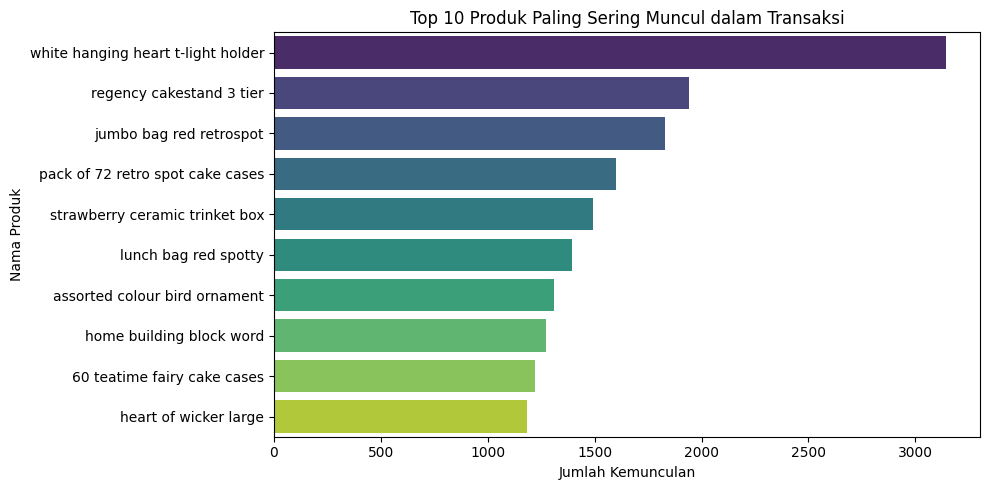

In [5]:
# Cek Top 10 produk paling sering dibeli (berdasarkan kemunculan di transaksi)
top_products = df_clean['product_name'].value_counts().head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=top_products.values, y=top_products.index, palette='viridis')
plt.title('Top 10 Produk Paling Sering Muncul dalam Transaksi')
plt.xlabel('Jumlah Kemunculan')
plt.ylabel('Nama Produk')
plt.tight_layout()
plt.show()

## **Pembentukan Matriks Keranjang (Binary Basket Matrix)**

Algoritma `apriori` pada `mlxtend` mewajibkan matriks transaksi bernilai **biner (`True`/`False` atau `0`/`1`)**. Oleh karena itu, hasil tabulasi silang antara `order_id` dan `product_name` harus dikonversi ke tipe boolean `(basket > 0)`.

In [6]:
# Buat matriks keranjang biner (True jika item ada dalam order_id, False jika tidak)
basket = pd.crosstab(df_clean['order_id'], df_clean['product_name'])
basket = (basket > 0)

print(f'Dimensi matriks basket: {basket.shape[0]:,} transaksi x {basket.shape[1]:,} produk')
basket.iloc[:5, :5]

Dimensi matriks basket: 18,140 transaksi x 3,911 produk


product_name,*boombox ipod classic,*usb office mirror ball,10 colour spaceboy pen,12 ass zinc christmas decorations,12 coloured party balloons
order_id,,,,,
493413,False,False,False,False,False
493414,False,False,False,False,False
493427,False,False,False,False,False
493428,False,False,False,False,False
493432,False,False,False,False,False


## **Ekstraksi Frequent Itemsets (Apriori) & Association Rules**

Pada tahap ini kita mengekstraksi kombinasi item yang sering muncul bersamaan menggunakan `apriori`, kemudian membentuk aturan asosiasi (`If Antecedent -> Then Consequent`) dengan metrik evaluasi utama:
- **Support:** Proporsi transaksi yang memuat itemset tersebut.
- **Confidence:** Peluang item *consequent* dibeli ketika item *antecedent* dibeli.
- **Lift:** Rasio peningkatan peluang pembelian *consequent* dibanding pembelian acak (`Lift > 1` menunjukkan asosiasi positif yang kuat).

In [7]:
# Ekstraksi Frequent Itemsets dengan min_support = 0.02 (2% dari total transaksi)
frequent_itemsets = apriori(basket, min_support=0.02, use_colnames=True, low_memory=True)
frequent_itemsets['length'] = frequent_itemsets['itemsets'].apply(lambda x: len(x))

print(f'Total frequent itemsets ditemukan: {len(frequent_itemsets)}')
frequent_itemsets.sort_values(by='support', ascending=False).head(10)

Total frequent itemsets ditemukan: 353


,support,itemsets,length
268,0.166373,(white hanging heart t-light holder),1
206,0.105347,(regency cakestand 3 tier),1
104,0.098401,(jumbo bag red retrospot),1
151,0.084895,(pack of 72 retro spot cake cases),1
245,0.078445,(strawberry ceramic trinket box),1
127,0.074587,(lunch bag red spotty),1
10,0.070232,(assorted colour bird ornament),1
89,0.067751,(home building block word),1
6,0.064002,(60 teatime fairy cake cases),1
87,0.062459,(heart of wicker large),1


In [8]:
# Tampilkan Association Rules dengan minimum Lift = 1.0
rules = association_rules(frequent_itemsets, metric='lift', min_threshold=1.0)

# Filter aturan yang kuat (misalnya confidence >= 0.5 dan lift >= 2.0)
strong_rules = rules[(rules['confidence'] >= 0.5) & (rules['lift'] >= 2.0)].copy()
strong_rules = strong_rules.sort_values(by=['lift', 'confidence'], ascending=False).reset_index(drop=True)

print(f'Total rules (lift >= 1.0): {len(rules)}')
print(f'Total strong rules (confidence >= 0.5 & lift >= 2.0): {len(strong_rules)}')
strong_rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(15)

Total rules (lift >= 1.0): 136
Total strong rules (confidence >= 0.5 & lift >= 2.0): 36


,antecedents,consequents,support,confidence,lift
0,(toilet metal sign),(bathroom metal sign),0.020562,0.759674,17.247170
1,(charlotte bag pink with white spots),(red spotty charlotte bag),0.026351,0.662968,14.181888
2,(red spotty charlotte bag),(charlotte bag pink with white spots),0.026351,0.563679,14.181888
3,(large popcorn holder),(small popcorn holder),0.020452,0.700000,13.595289
4,(strawberry charlotte bag),(red spotty charlotte bag),0.020783,0.629382,13.463437
5,(single heart zinc t-light holder),(hanging heart zinc t-light holder),0.020728,0.626667,13.051359
6,(vintage heads and tails card game),(vintage snap cards),0.020783,0.615008,12.634482
7,(charlotte bag pink with white spots),(charlotte bag suki design),0.021058,0.529820,12.596238
8,(charlotte bag suki design),(charlotte bag pink with white spots),0.021058,0.500655,12.596238
9,(paper chain kit vintage christmas),(paper chain kit 50's christmas),0.020287,0.519774,11.583170


In [14]:
strong_rules

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,(toilet metal sign),(bathroom metal sign),0.027067,0.044046,0.020562,0.759674,17.247170,1.0,0.019370,3.977740,0.968227,0.406761,0.748601,0.613254
1,(charlotte bag pink with white spots),(red spotty charlotte bag),0.039746,0.046748,0.026351,0.662968,14.181888,1.0,0.024493,2.828375,0.967960,0.438130,0.646440,0.613324
2,(red spotty charlotte bag),(charlotte bag pink with white spots),0.046748,0.039746,0.026351,0.563679,14.181888,1.0,0.024493,2.200797,0.975070,0.438130,0.545619,0.613324
3,(large popcorn holder),(small popcorn holder),0.029217,0.051488,0.020452,0.700000,13.595289,1.0,0.018948,3.161705,0.954328,0.339433,0.683715,0.548608
4,(strawberry charlotte bag),(red spotty charlotte bag),0.033021,0.046748,0.020783,0.629382,13.463437,1.0,0.019239,2.572064,0.957337,0.352336,0.611207,0.536979
5,(single heart zinc t-light holder),(hanging heart zinc t-light holder),0.033076,0.048015,0.020728,0.626667,13.051359,1.0,0.019140,2.549959,0.954966,0.343379,0.607837,0.529177
6,(vintage heads and tails card game),(vintage snap cards),0.033793,0.048677,0.020783,0.615008,12.634482,1.0,0.019138,2.471021,0.953058,0.336908,0.595309,0.520981
7,(charlotte bag pink with white spots),(charlotte bag suki design),0.039746,0.042062,0.021058,0.529820,12.596238,1.0,0.019387,2.037385,0.958717,0.346642,0.509175,0.515238
8,(charlotte bag suki design),(charlotte bag pink with white spots),0.042062,0.039746,0.021058,0.500655,12.596238,1.0,0.019387,1.923028,0.961034,0.346642,0.479987,0.515238
9,(paper chain kit vintage christmas),(paper chain kit 50's christmas),0.039030,0.044873,0.020287,0.519774,11.583170,1.0,0.018535,1.988911,0.950776,0.318891,0.497212,0.485931


## **Visualisasi & Interpretasi Association Rules**

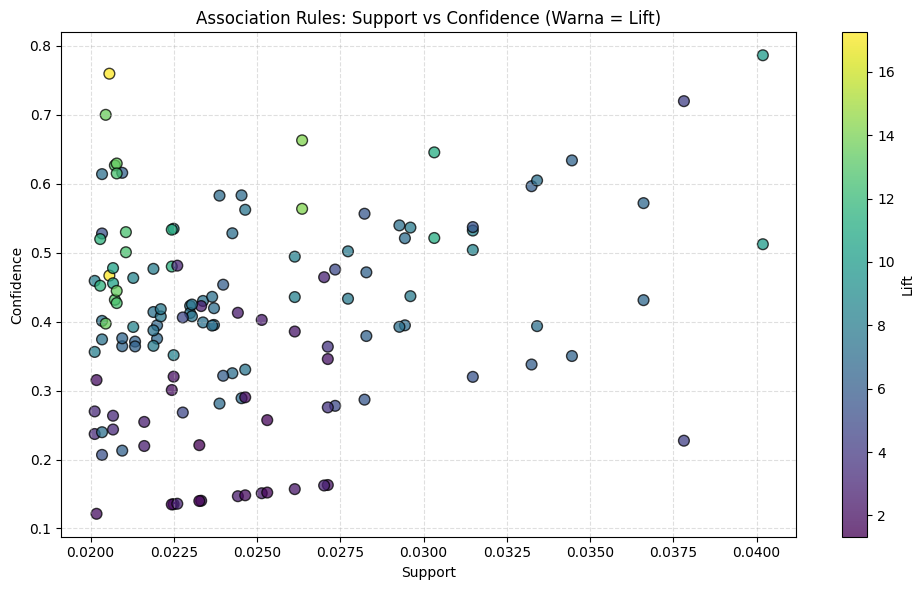

In [9]:
# Scatter plot Support vs Confidence dengan warna berdasarkan Lift
if len(rules) > 0:
    plt.figure(figsize=(10, 6))
    scatter = plt.scatter(
        rules['support'],
        rules['confidence'],
        c=rules['lift'],
        cmap='viridis',
        alpha=0.75,
        edgecolors='k',
        s=60
    )
    plt.colorbar(scatter, label='Lift')
    plt.title('Association Rules: Support vs Confidence (Warna = Lift)')
    plt.xlabel('Support')
    plt.ylabel('Confidence')
    plt.grid(True, linestyle='--', alpha=0.4)
    plt.tight_layout()
    plt.show()
else:
    print('Tidak ada rules yang memenuhi threshold. Turunkan nilai min_support.')

In [10]:
# Menampilkan ringkasan aturan terbaik dalam format kalimat yang mudah dibaca
for idx, row in strong_rules.head(10).iterrows():
    ant = ', '.join(list(row['antecedents']))
    con = ', '.join(list(row['consequents']))
    print(f"{idx+1}. Jika membeli [{ant}] -> maka membeli [{con}] "
          f"(Support: {row['support']:.3f}, Confidence: {row['confidence']:.2%}, Lift: {row['lift']:.2f})")

1. Jika membeli [toilet metal sign] -> maka membeli [bathroom metal sign] (Support: 0.021, Confidence: 75.97%, Lift: 17.25)
2. Jika membeli [charlotte bag pink with white spots] -> maka membeli [red spotty charlotte bag] (Support: 0.026, Confidence: 66.30%, Lift: 14.18)
3. Jika membeli [red spotty charlotte bag] -> maka membeli [charlotte bag pink with white spots] (Support: 0.026, Confidence: 56.37%, Lift: 14.18)
4. Jika membeli [large popcorn holder] -> maka membeli [small popcorn holder] (Support: 0.020, Confidence: 70.00%, Lift: 13.60)
5. Jika membeli [strawberry charlotte bag] -> maka membeli [red spotty charlotte bag] (Support: 0.021, Confidence: 62.94%, Lift: 13.46)
6. Jika membeli [single heart zinc t-light holder] -> maka membeli [hanging heart zinc t-light holder] (Support: 0.021, Confidence: 62.67%, Lift: 13.05)
7. Jika membeli [vintage heads and tails card game] -> maka membeli [vintage snap cards] (Support: 0.021, Confidence: 61.50%, Lift: 12.63)
8. Jika membeli [charlotte